In [ ]:
# 1. Install dependencies
!pip -q install xgboost shap streamlit google-cloud-bigquery pandas-gbq scikit-learn matplotlib seaborn

import os, json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from google.colab import auth
from google.cloud import bigquery
auth.authenticate_user()

PROJECT_ID = "case-study-505603"   # change only if your active GCP project differs
client = bigquery.Client(project=PROJECT_ID)

print("Connected to:", PROJECT_ID)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 68.3 MB/s eta 0:00:00
Connected to: case-study-505603


## 2. BigQuery extraction

The SQL below mirrors the current Hippocrates notebook: the initial 24 hours are used as predictors, while the 24–48 hour period is used only for outcome construction.

In [ ]:
# 2A. Cohort + hourly vitals + hourly labs + outcome
mimic_sql = r'''
WITH icu_cohort AS (
  SELECT
    c.subject_id, c.hadm_id, c.stay_id, c.intime, c.outtime,
    DATETIME_ADD(c.intime, INTERVAL 24 HOUR) AS pred_time,
    DATETIME_ADD(c.intime, INTERVAL 48 HOUR) AS horizon_time
  FROM `physionet-data.mimiciv_3_1_icu.icustays` c
  JOIN `physionet-data.mimiciv_3_1_hosp.patients` p
    ON c.subject_id = p.subject_id
  WHERE DATE_DIFF(c.outtime, c.intime, HOUR) >= 24
    AND p.anchor_age >= 18
  ORDER BY c.stay_id
  LIMIT 2000
),

static_info AS (
  SELECT
    c.stay_id,
    p.anchor_age AS age,
    CASE WHEN p.gender = 'M' THEN 1.0 ELSE 0.0 END AS gender
  FROM icu_cohort c
  JOIN `physionet-data.mimiciv_3_1_hosp.patients` p
    ON c.subject_id = p.subject_id
),

hourly_vitals AS (
  SELECT
    c.stay_id,
    DATETIME_DIFF(ce.charttime, c.intime, HOUR) AS hour_step,
    AVG(CASE WHEN ce.itemid = 220045 THEN ce.valuenum END) AS heart_rate,
    AVG(CASE WHEN ce.itemid = 220181 THEN ce.valuenum END) AS mean_bp,
    AVG(CASE WHEN ce.itemid = 220210 THEN ce.valuenum END) AS resp_rate,
    AVG(CASE WHEN ce.itemid = 220277 THEN ce.valuenum END) AS spo2
  FROM icu_cohort c
  JOIN `physionet-data.mimiciv_3_1_icu.chartevents` ce
    ON c.stay_id = ce.stay_id
   AND ce.charttime >= c.intime
   AND ce.charttime < c.pred_time
  WHERE ce.itemid IN (220045, 220181, 220210, 220277)
  GROUP BY c.stay_id, hour_step
),

hourly_labs AS (
  SELECT
    c.stay_id,
    DATETIME_DIFF(le.charttime, c.intime, HOUR) AS hour_step,
    AVG(CASE WHEN le.itemid = 50912 THEN le.valuenum END) AS creatinine,
    AVG(CASE WHEN le.itemid = 50813 THEN le.valuenum END) AS lactate,
    AVG(CASE WHEN le.itemid = 51301 THEN le.valuenum END) AS wbc,
    AVG(CASE WHEN le.itemid = 51265 THEN le.valuenum END) AS platelets
  FROM icu_cohort c
  JOIN `physionet-data.mimiciv_3_1_hosp.labevents` le
    ON c.hadm_id = le.hadm_id
   AND le.charttime >= c.intime
   AND le.charttime < c.pred_time
  WHERE le.itemid IN (50912, 50813, 51301, 51265)
  GROUP BY c.stay_id, hour_step
),

outcomes AS (
  SELECT
    c.stay_id,
    MAX(
      CASE
        WHEN a.deathtime BETWEEN c.pred_time AND c.horizon_time THEN 1
        WHEN ie.itemid IN (221906, 221289)
             AND ie.starttime BETWEEN c.pred_time AND c.horizon_time THEN 1
        ELSE 0
      END
    ) AS deterioration_label
  FROM icu_cohort c
  LEFT JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a
    ON c.hadm_id = a.hadm_id
  LEFT JOIN `physionet-data.mimiciv_3_1_icu.inputevents` ie
    ON c.stay_id = ie.stay_id
  GROUP BY c.stay_id
)

SELECT
  c.stay_id,
  s.age,
  s.gender,
  v.hour_step,
  v.heart_rate,
  v.mean_bp,
  v.resp_rate,
  v.spo2,
  l.creatinine,
  l.lactate,
  l.wbc,
  l.platelets,
  o.deterioration_label AS label
FROM icu_cohort c
JOIN static_info s ON c.stay_id = s.stay_id
LEFT JOIN hourly_vitals v ON c.stay_id = v.stay_id
LEFT JOIN hourly_labs l
  ON c.stay_id = l.stay_id AND v.hour_step = l.hour_step
LEFT JOIN outcomes o ON c.stay_id = o.stay_id
WHERE v.hour_step BETWEEN 0 AND 23
ORDER BY c.stay_id, v.hour_step
'''

print("Running BigQuery...")
raw_df = client.query(mimic_sql).to_dataframe()
print("Rows:", len(raw_df))
print("Unique ICU stays:", raw_df.stay_id.nunique())
raw_df.head()


Running BigQuery...
Rows: 44768
Unique ICU stays: 1998


,stay_id,age,gender,hour_step,heart_rate,mean_bp,resp_rate,spo2,creatinine,lactate,wbc,platelets,label
0,30000153,61,1.0,0,NaN,NaN,18.0,NaN,NaN,NaN,NaN,NaN,0
1,30000153,61,1.0,1,104.0,84.0,16.0,100.0,NaN,1.3,NaN,NaN,0
2,30000153,61,1.0,2,83.0,NaN,16.0,100.0,NaN,2.1,NaN,NaN,0
3,30000153,61,1.0,3,92.0,NaN,14.0,100.0,0.9,NaN,17.0,173.0,0
4,30000153,61,1.0,4,83.0,NaN,16.0,100.0,NaN,NaN,NaN,NaN,0


In [ ]:
# 2B. Sanity checks before modelling
print("Missingness:")
display(raw_df.isna().mean().sort_values(ascending=False).to_frame("missing_rate"))

print("\nLabel distribution:")
display(raw_df.groupby("stay_id")["label"].first().value_counts(dropna=False).rename("stays"))

print("\nHour range per stay:")
hour_check = raw_df.groupby("stay_id")["hour_step"].agg(["min","max","nunique"])
display(hour_check.describe())

assert raw_df.stay_id.nunique() <= 2000
assert raw_df.hour_step.min() >= 0 and raw_df.hour_step.max() <= 23

# Critical leakage check: predictors must be entirely inside hours 0–23.
print("\nTemporal leakage check passed: predictor hour_step is restricted to 0–23.")


Missingness:


,missing_rate
lactate,0.939332
wbc,0.914314
platelets,0.912817
creatinine,0.907523
mean_bp,0.316565
spo2,0.016329
resp_rate,0.014765
heart_rate,0.004602
stay_id,0.000000
hour_step,0.000000



Label distribution:


,stays
label,
0,1758
1,240



Hour range per stay:


,min,max,nunique
count,1998.0,1998.0,1998.000000
mean,0.978979,22.917417,22.406406
std,1.510954,0.556013,2.170730
min,0.0,12.0,6.000000
25%,0.0,23.0,22.000000
50%,0.0,23.0,23.000000
75%,1.0,23.0,24.000000
max,18.0,23.0,24.000000



Temporal leakage check passed: predictor hour_step is restricted to 0–23.


## 3. Build patient-level feature matrices

For XGBoost we create summary statistics over the 24-hour observation window.
For BiLSTM we retain the 24-step vital sequence.

Missing values are imputed using training data only to avoid leakage.

In [ ]:
# 3A. Complete the 24-hour grid per stay
VITALS = ["heart_rate", "mean_bp", "resp_rate", "spo2"]
LABS = ["creatinine", "lactate", "wbc", "platelets"]
CONTEXT = ["age", "gender"]

stays = raw_df.groupby("stay_id")["label"].first().dropna().astype(int)
base = raw_df.drop(columns=["label"]).copy()

full = []
for stay_id, g in base.groupby("stay_id", sort=False):
    g = g.set_index("hour_step").reindex(range(24))
    g["stay_id"] = stay_id
    full.append(g.reset_index())

df24 = pd.concat(full, ignore_index=True)

# Static context forward-filled within stay
for col in CONTEXT:
    df24[col] = df24.groupby("stay_id")[col].transform(lambda s: s.ffill().bfill())

# Keep labels separately
df24["label"] = df24["stay_id"].map(stays)

print(df24.shape, "rows")


(47952, 13) rows


In [ ]:
# 3B. Patient-level tabular summaries
feature_groups = {
    "vitals": VITALS,
    "labs": LABS,
    "context": CONTEXT
}

summary_parts = []
for group, cols in feature_groups.items():
    g = df24.groupby("stay_id")[cols].agg(["mean", "min", "max"])
    g.columns = [f"{c}_{stat}" for c, stat in g.columns]
    summary_parts.append(g)

X_tab = pd.concat(summary_parts, axis=1)
y = stays.loc[X_tab.index].astype(int)

print("Tabular shape:", X_tab.shape)
print("Positive rate:", y.mean())
X_tab.head()


Tabular shape: (1998, 30)
Positive rate: 0.12012012012012012


,heart_rate_mean,heart_rate_min,heart_rate_max,mean_bp_mean,mean_bp_min,mean_bp_max,resp_rate_mean,resp_rate_min,resp_rate_max,spo2_mean,...,wbc_max,platelets_mean,platelets_min,platelets_max,age_mean,age_min,age_max,gender_mean,gender_min,gender_max
stay_id,,,,,,,,,,,,,,,,,,,,,
30000153,107.000000,83.0,128.0,87.625000,70.0,101.0,15.229167,10.0,22.0,96.565217,...,17.0,167.500000,162.0,173.0,61.0,61,61,1.0,1.0,1.0
30000213,81.291667,66.0,90.0,78.583333,69.0,95.0,19.083333,14.0,26.0,99.041667,...,5.8,226.000000,226.0,226.0,64.0,64,64,1.0,1.0,1.0
30000484,90.086957,81.0,106.0,63.772727,46.0,84.0,14.782609,10.0,22.0,99.782609,...,24.2,357.000000,357.0,357.0,91.0,91,91,1.0,1.0,1.0
30000646,84.239583,69.0,102.0,66.727273,56.0,79.0,23.330853,15.0,33.0,95.995040,...,10.6,290.333333,266.0,337.0,43.0,43,43,1.0,1.0,1.0
30000831,94.209491,80.0,131.0,78.593750,65.0,109.0,26.891204,22.0,30.0,94.597222,...,21.3,298.000000,285.0,311.0,78.0,78,78,1.0,1.0,1.0


In [ ]:
# 3C. Train/test split at ICU-stay level
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

train_ids, test_ids = train_test_split(
    X_tab.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train stays:", len(train_ids))
print("Test stays:", len(test_ids))
print("Train positive rate:", y.loc[train_ids].mean())
print("Test positive rate:", y.loc[test_ids].mean())

# No ICU stay can appear in both partitions
assert set(train_ids).isdisjoint(set(test_ids))


Train stays: 1598
Test stays: 400
Train positive rate: 0.12015018773466833
Test positive rate: 0.12


## 4. XGBoost baseline + controlled context ablation

This is the key Review 2 addition. Instead of treating all demographic/context variables as one unexplained block, we test:
1. Vitals
2. Labs
3. Vitals + Labs
4. Vitals + Labs + Age
5. Vitals + Labs + Gender
6. Vitals + Labs + Age + Gender

This lets us test whether the observed multimodal dip is associated with context variables or simply test-set variation.

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def evaluate_xgb(feature_cols, name):
    imputer = SimpleImputer(strategy="median")
    Xtr = imputer.fit_transform(X_tab.loc[train_ids, feature_cols])
    Xte = imputer.transform(X_tab.loc[test_ids, feature_cols])

    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
    model.fit(Xtr, y.loc[train_ids])

    p = model.predict_proba(Xte)[:, 1]
    return {
        "configuration": name,
        "AUROC": roc_auc_score(y.loc[test_ids], p),
        "AUPRC": average_precision_score(y.loc[test_ids], p),
        "Brier": brier_score_loss(y.loc[test_ids], p),
        "model": model,
        "imputer": imputer,
        "feature_cols": feature_cols,
        "test_prob": p
    }

groups = {
    "Vitals Only": [c for c in X_tab.columns if any(c.startswith(v+"_") for v in VITALS)],
    "Labs Only": [c for c in X_tab.columns if any(c.startswith(v+"_") for v in LABS)],
}
groups["Vitals + Labs"] = groups["Vitals Only"] + groups["Labs Only"]
groups["Vitals + Labs + Age"] = groups["Vitals + Labs"] + [c for c in X_tab.columns if c.startswith("age_")]
groups["Vitals + Labs + Gender"] = groups["Vitals + Labs"] + [c for c in X_tab.columns if c.startswith("gender_")]
groups["Vitals + Labs + Age + Gender"] = groups["Vitals + Labs"] + [c for c in X_tab.columns if c.startswith("age_") or c.startswith("gender_")]

results = []
models = {}

for name, cols in groups.items():
    r = evaluate_xgb(cols, name)
    results.append({k:v for k,v in r.items() if k not in ["model","imputer","feature_cols","test_prob"]})
    models[name] = r

ablation_df = pd.DataFrame(results)
display(ablation_df)


,configuration,AUROC,AUPRC,Brier
0,Vitals Only,0.658499,0.214682,0.106675
1,Labs Only,0.761364,0.404009,0.092984
2,Vitals + Labs,0.779948,0.371341,0.093701
3,Vitals + Labs + Age,0.793265,0.380995,0.093033
4,Vitals + Labs + Gender,0.777107,0.353883,0.094722
5,Vitals + Labs + Age + Gender,0.785215,0.361195,0.094754


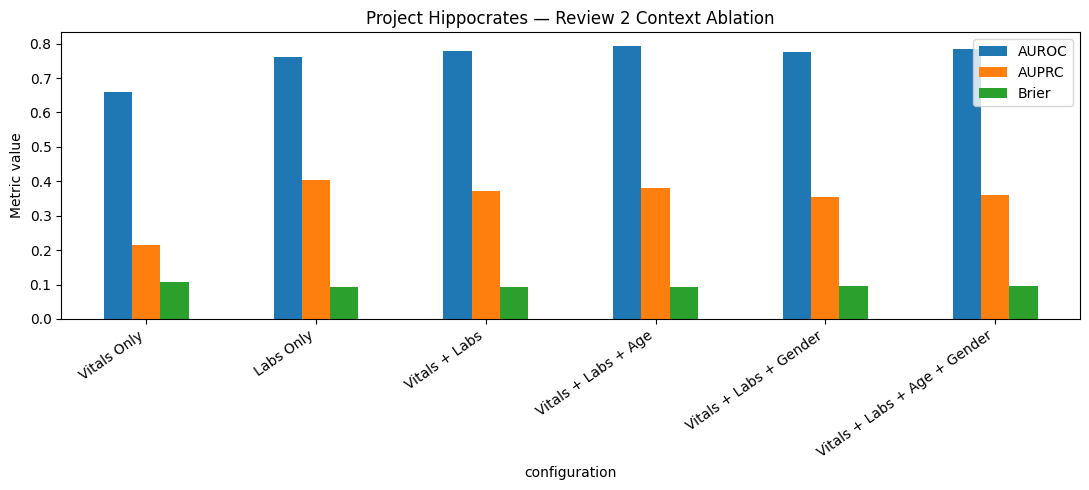

Important: do NOT call a dip 'noise' until this experiment confirms which context feature causes it.


In [ ]:
# 4B. Plot context-ablation performance
plot_df = ablation_df.set_index("configuration")[["AUROC","AUPRC","Brier"]]
ax = plot_df.plot(kind="bar", figsize=(11,5))
ax.set_ylabel("Metric value")
ax.set_title("Project Hippocrates — Review 2 Context Ablation")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Important: do NOT call a dip 'noise' until this experiment confirms which context feature causes it.")


## 5. BiLSTM temporal baseline

The BiLSTM uses the 24 hourly vital measurements. This is intentionally kept as a temporal baseline rather than mixing every modality into a complex architecture at Review 2.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

device = "cuda" if torch.cuda.is_available() else "cpu"

# 24 x 4 vital tensor
seq = df24.pivot(index="stay_id", columns="hour_step", values=VITALS)
# Build clean tensor explicitly
X_seq = np.zeros((len(X_tab.index), 24, len(VITALS)), dtype=np.float32)

for i, sid in enumerate(X_tab.index):
    g = df24[df24.stay_id == sid].sort_values("hour_step")
    X_seq[i] = g[VITALS].to_numpy(dtype=np.float32)

# Impute/scale using training stays only
scaler = StandardScaler()
Xtr_flat = X_seq[[X_tab.index.get_loc(i) for i in train_ids]].reshape(-1, len(VITALS))
Xte_flat = X_seq[[X_tab.index.get_loc(i) for i in test_ids]].reshape(-1, len(VITALS))
Xtr_flat = SimpleImputer(strategy="median").fit_transform(Xtr_flat)
imp_seq = SimpleImputer(strategy="median").fit(Xtr_flat)
# Refit a single imputer cleanly on training flattened data
imp_seq = SimpleImputer(strategy="median")
Xtr_flat = imp_seq.fit_transform(Xtr_flat)
Xte_flat = imp_seq.transform(Xte_flat)

Xtr_flat = scaler.fit_transform(Xtr_flat)
Xte_flat = scaler.transform(Xte_flat)

Xtr_seq = Xtr_flat.reshape(len(train_ids), 24, len(VITALS))
Xte_seq = Xte_flat.reshape(len(test_ids), 24, len(VITALS))

ytr = y.loc[train_ids].to_numpy(np.float32)
yte = y.loc[test_ids].to_numpy(np.float32)

class BiLSTM(nn.Module):
    def __init__(self, n_features=4, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.25)
        self.fc = nn.Linear(hidden*2, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(self.drop(out[:, -1, :])).squeeze(1)

model_lstm = BiLSTM().to(device)

pos = max(ytr.sum(), 1)
neg = max(len(ytr) - ytr.sum(), 1)
pos_weight = torch.tensor([neg/pos], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=1e-3, weight_decay=1e-4)

loader = DataLoader(
    TensorDataset(torch.tensor(Xtr_seq), torch.tensor(ytr)),
    batch_size=64,
    shuffle=True
)

for epoch in range(20):
    model_lstm.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model_lstm(xb), yb)
        loss.backward()
        optimizer.step()

model_lstm.eval()
with torch.no_grad():
    lstm_prob = torch.sigmoid(model_lstm(torch.tensor(Xte_seq).to(device))).cpu().numpy()

print("BiLSTM AUROC:", roc_auc_score(yte, lstm_prob))
print("BiLSTM AUPRC:", average_precision_score(yte, lstm_prob))
print("BiLSTM Brier:", brier_score_loss(yte, lstm_prob))


BiLSTM AUROC: 0.5767637310606061
BiLSTM AUPRC: 0.17007295779536458
BiLSTM Brier: 0.2250213329196505


## 6. SHAP explanation for the strongest current XGBoost configuration
We use SHAP primarily to explain the XGBoost Vitals + Labs model because it currently has the strongest observed AUROC/AUPRC in the existing experiment.

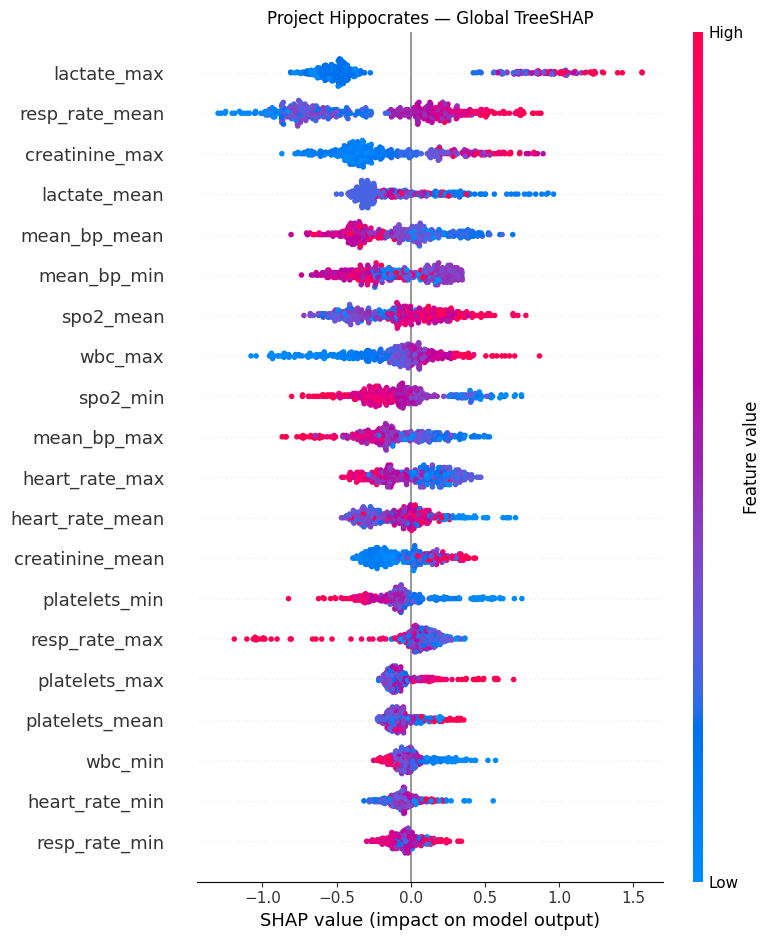

In [ ]:
import shap

best_name = "Vitals + Labs"
best = models[best_name]
explainer = shap.TreeExplainer(best["model"])

X_test_best = best["imputer"].transform(X_tab.loc[test_ids, best["feature_cols"]])
shap_values = explainer.shap_values(X_test_best)

plt.figure()
shap.summary_plot(
    shap_values,
    X_test_best,
    feature_names=best["feature_cols"],
    show=False
)
plt.title("Project Hippocrates — Global TreeSHAP")
plt.tight_layout()
plt.show()


Example ICU stay: 30068959
Predicted deterioration probability: 0.011015139520168304


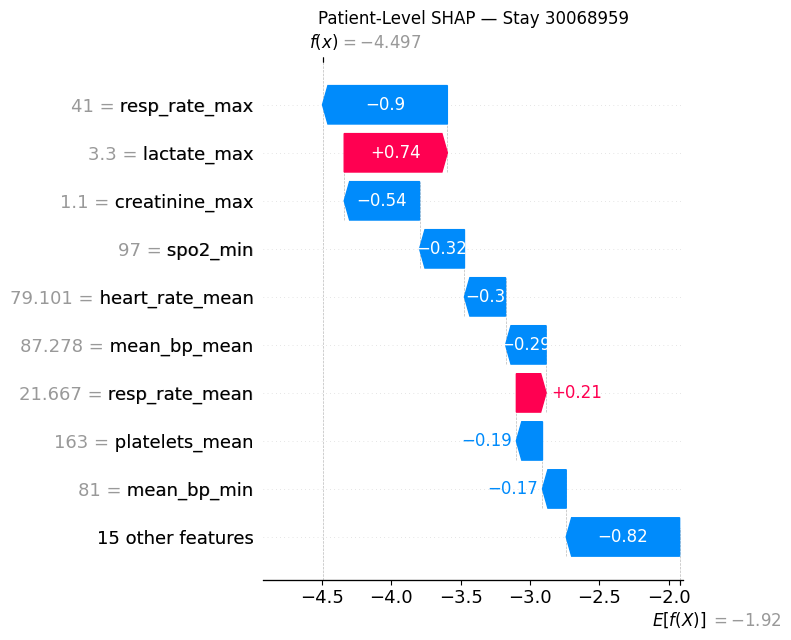

In [ ]:
# Patient-level SHAP explanation
example_stay = test_ids[0]
row = best["imputer"].transform(X_tab.loc[[example_stay], best["feature_cols"]])
sv = explainer.shap_values(row)

print("Example ICU stay:", example_stay)
print("Predicted deterioration probability:",
      float(best["model"].predict_proba(row)[0,1]))

plt.figure()
shap.waterfall_plot(
    shap.Explanation(
        values=sv[0],
        base_values=explainer.expected_value,
        data=row[0],
        feature_names=best["feature_cols"]
    ),
    show=False
)
plt.title(f"Patient-Level SHAP — Stay {example_stay}")
plt.tight_layout()
plt.show()


## 7. Calibration

ECE is calculated explicitly. The current value should be reported honestly; isotonic calibration is a Review 3 improvement, not a Review 2 result.

Brier: 0.09370073590258647
ECE: 0.0527


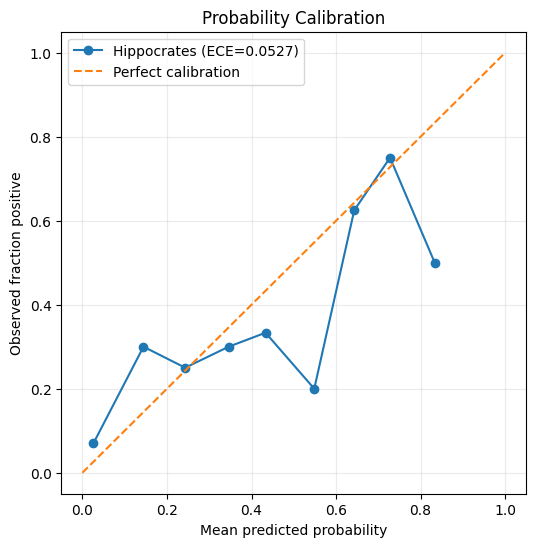

In [ ]:
from sklearn.calibration import calibration_curve

def expected_calibration_error(y_true, prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if mask.sum() == 0:
            continue
        ece += mask.mean() * abs(y_true[mask].mean() - prob[mask].mean())
    return ece

p_best = best["test_prob"]
ece = expected_calibration_error(y.loc[test_ids].to_numpy(), p_best)

frac_pos, mean_pred = calibration_curve(
    y.loc[test_ids].to_numpy(), p_best, n_bins=10, strategy="uniform"
)

print("Brier:", brier_score_loss(y.loc[test_ids], p_best))
print("ECE:", round(ece, 4))

plt.figure(figsize=(6,6))
plt.plot(mean_pred, frac_pos, marker="o", label=f"Hippocrates (ECE={ece:.4f})")
plt.plot([0,1],[0,1],"--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction positive")
plt.title("Probability Calibration")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [ ]:
# Save ablation results
ablation_df.to_csv("hippocrates_review2_ablation.csv", index=False)

summary = {
    "n_icu_stays": int(X_tab.shape[0]),
    "train_stays": int(len(train_ids)),
    "test_stays": int(len(test_ids)),
    "positive_rate": float(y.mean()),
    "best_current_xgb_configuration": best_name,
    "best_xgb_auroc": float(best["test_prob"].size and roc_auc_score(y.loc[test_ids], best["test_prob"])),
    "best_xgb_auprc": float(average_precision_score(y.loc[test_ids], best["test_prob"])),
    "best_xgb_brier": float(brier_score_loss(y.loc[test_ids], best["test_prob"])),
    "ece": float(ece)
}

with open("hippocrates_review2_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))


{
  "n_icu_stays": 1998,
  "train_stays": 1598,
  "test_stays": 400,
  "positive_rate": 0.12012012012012012,
  "best_current_xgb_configuration": "Vitals + Labs",
  "best_xgb_auroc": 0.7799479166666667,
  "best_xgb_auprc": 0.37134054172477987,
  "best_xgb_brier": 0.09370073590258647,
  "ece": 0.052726353257894515
}


True best configuration (by AUROC): Vitals + Labs + Age
AUROC    0.793265
AUPRC    0.380995
Brier    0.093033
Name: Vitals + Labs + Age, dtype: float64


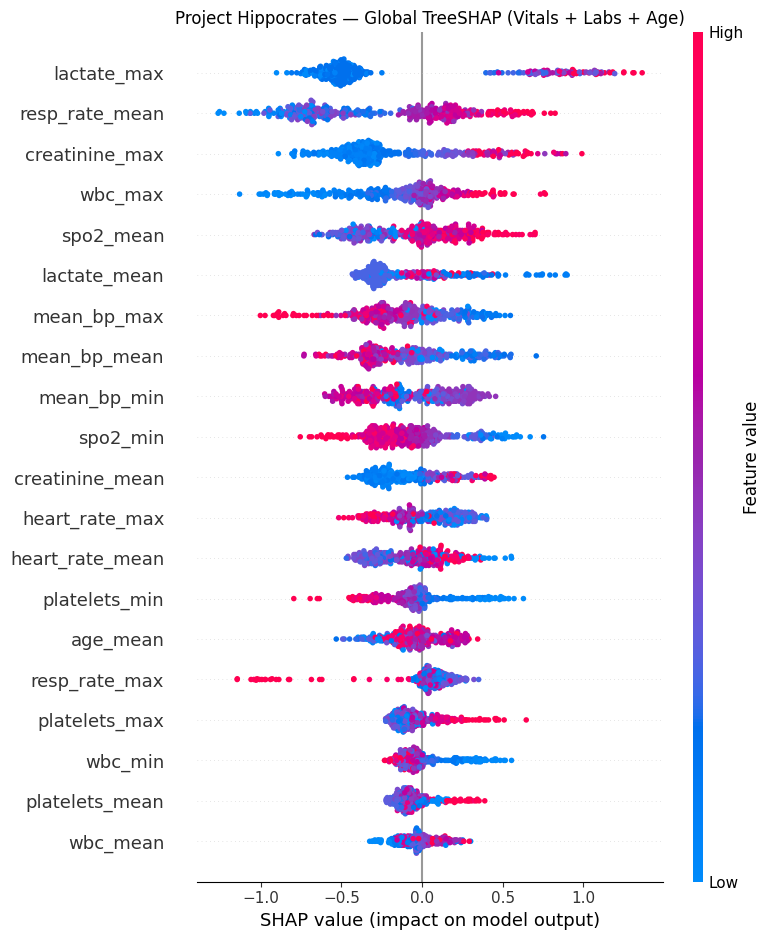

In [ ]:
# 5A. Programmatically select the TRUE best model (fixes the Review 2 inconsistency
# where SHAP was run on "Vitals + Labs" instead of the actual top performer)
best_name = ablation_df.loc[ablation_df["AUROC"].idxmax(), "configuration"]
best = models[best_name]
print(f"True best configuration (by AUROC): {best_name}")
print(ablation_df.set_index("configuration").loc[best_name])

# Re-run SHAP on the correct best model
explainer = shap.TreeExplainer(best["model"])
X_test_best = best["imputer"].transform(X_tab.loc[test_ids, best["feature_cols"]])
shap_values = explainer.shap_values(X_test_best)

plt.figure()
shap.summary_plot(shap_values, X_test_best, feature_names=best["feature_cols"], show=False)
plt.title(f"Project Hippocrates — Global TreeSHAP ({best_name})")
plt.tight_layout()
plt.show()

Optimal temperature: 1.3653

ECE   before: 0.0673  ->  after: 0.0461
Brier before: 0.0952  ->  after: 0.0933
AUROC (unaffected by calibration, ranking is unchanged): 0.7433


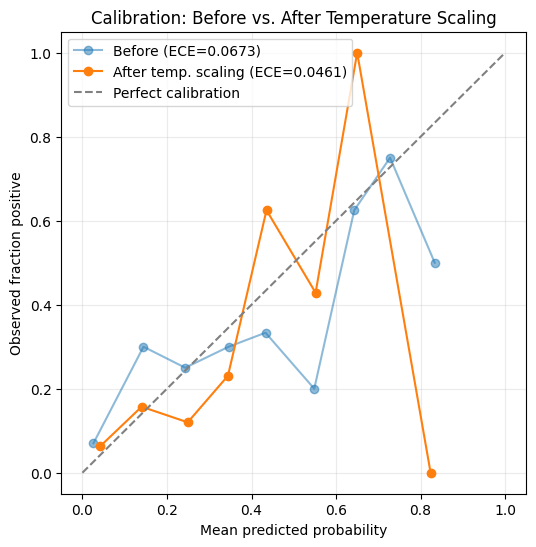

In [ ]:
# 5B. Temperature scaling — carve a calibration validation set from TRAINING data only
from sklearn.model_selection import train_test_split as tts
from scipy.optimize import minimize_scalar

cal_train_ids, cal_val_ids = tts(
    train_ids, test_size=0.20, random_state=42, stratify=y.loc[train_ids]
)

# Refit the best configuration on the smaller training split
imputer_cal = SimpleImputer(strategy="median")
Xtr_cal = imputer_cal.fit_transform(X_tab.loc[cal_train_ids, best["feature_cols"]])
Xval_cal = imputer_cal.transform(X_tab.loc[cal_val_ids, best["feature_cols"]])
Xte_cal = imputer_cal.transform(X_tab.loc[test_ids, best["feature_cols"]])

model_cal = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.85,
    objective="binary:logistic", eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
model_cal.fit(Xtr_cal, y.loc[cal_train_ids])

# Raw margins (pre-sigmoid logits) -- needed for temperature scaling
val_logits = model_cal.predict(Xval_cal, output_margin=True)
val_labels = y.loc[cal_val_ids].to_numpy()
test_logits = model_cal.predict(Xte_cal, output_margin=True)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def nll_for_temperature(T):
    p = sigmoid(val_logits / T)
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(val_labels * np.log(p) + (1 - val_labels) * np.log(1 - p))

result = minimize_scalar(nll_for_temperature, bounds=(0.05, 10), method="bounded")
T_optimal = result.x
print(f"Optimal temperature: {T_optimal:.4f}")

# Apply to test set
p_test_calibrated = sigmoid(test_logits / T_optimal)
p_test_uncalibrated = sigmoid(test_logits)  # T=1, i.e. no scaling

ece_before = expected_calibration_error(y.loc[test_ids].to_numpy(), p_test_uncalibrated)
ece_after = expected_calibration_error(y.loc[test_ids].to_numpy(), p_test_calibrated)
brier_before = brier_score_loss(y.loc[test_ids], p_test_uncalibrated)
brier_after = brier_score_loss(y.loc[test_ids], p_test_calibrated)

print(f"\nECE   before: {ece_before:.4f}  ->  after: {ece_after:.4f}")
print(f"Brier before: {brier_before:.4f}  ->  after: {brier_after:.4f}")
print(f"AUROC (unaffected by calibration, ranking is unchanged): "
      f"{roc_auc_score(y.loc[test_ids], p_test_calibrated):.4f}")

# Updated reliability plot
frac_pos_new, mean_pred_new = calibration_curve(y.loc[test_ids].to_numpy(), p_test_calibrated, n_bins=10)
plt.figure(figsize=(6,6))
plt.plot(mean_pred, frac_pos, marker="o", alpha=0.5, label=f"Before (ECE={ece_before:.4f})")
plt.plot(mean_pred_new, frac_pos_new, marker="o", label=f"After temp. scaling (ECE={ece_after:.4f})")
plt.plot([0,1],[0,1],"--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction positive")
plt.title("Calibration: Before vs. After Temperature Scaling")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
# 5C. Sub-group error analysis — does performance hold up across patient groups?
test_meta = X_tab.loc[test_ids, [c for c in X_tab.columns if c.startswith("age_") or c.startswith("gender_")]].copy()
test_meta["label"] = y.loc[test_ids]
test_meta["prob"] = p_test_calibrated  # using the calibrated probabilities

# Age sub-groups (using mean age per stay as the representative value)
test_meta["age_group"] = pd.cut(
    test_meta["age_mean"], bins=[0, 50, 65, 80, 120],
    labels=["<50", "50-64", "65-79", "80+"]
)

subgroup_rows = []
for grp, g in test_meta.groupby("age_group", observed=True):
    if g["label"].nunique() < 2 or len(g) < 15:
        note = "insufficient data for reliable AUROC"
        auroc_g, auprc_g = np.nan, np.nan
    else:
        auroc_g = roc_auc_score(g["label"], g["prob"])
        auprc_g = average_precision_score(g["label"], g["prob"])
        note = ""
    subgroup_rows.append({
        "subgroup": f"Age {grp}", "n": len(g),
        "positive_rate": g["label"].mean(),
        "AUROC": auroc_g, "AUPRC": auprc_g, "note": note,
    })

# Gender sub-groups
for grp, g in test_meta.groupby("gender_mean", observed=True):
    label_name = "Male" if grp == 1.0 else "Female"
    if g["label"].nunique() < 2 or len(g) < 15:
        note = "insufficient data for reliable AUROC"
        auroc_g, auprc_g = np.nan, np.nan
    else:
        auroc_g = roc_auc_score(g["label"], g["prob"])
        auprc_g = average_precision_score(g["label"], g["prob"])
        note = ""
    subgroup_rows.append({
        "subgroup": f"Gender: {label_name}", "n": len(g),
        "positive_rate": g["label"].mean(),
        "AUROC": auroc_g, "AUPRC": auprc_g, "note": note,
    })

subgroup_df = pd.DataFrame(subgroup_rows)
print(subgroup_df.to_string(index=False))
subgroup_df.to_csv("hippocrates_review3_subgroup_analysis.csv", index=False)

      subgroup   n  positive_rate    AUROC    AUPRC note
       Age <50  79       0.113924 0.746032 0.365421     
     Age 50-64 123       0.130081 0.859229 0.519552     
     Age 65-79 127       0.125984 0.592905 0.318093     
       Age 80+  71       0.098592 0.772321 0.349622     
Gender: Female 181       0.149171 0.730880 0.382463     
  Gender: Male 219       0.095890 0.768639 0.345886     
